# Lab 2: Path finding (BFS, DFS and A*)
Environment (Anaconda): `conda activate ailab`, then `jupyter notebook`. Run cells top to bottom with **Shift+Enter**.

**Problem:** a robot moves on a grid map (4 directions, cost 1 per move) from START to GOAL. We compare how many cells each algorithm opens and how long the path is.

## Cell 1: Setup and random map

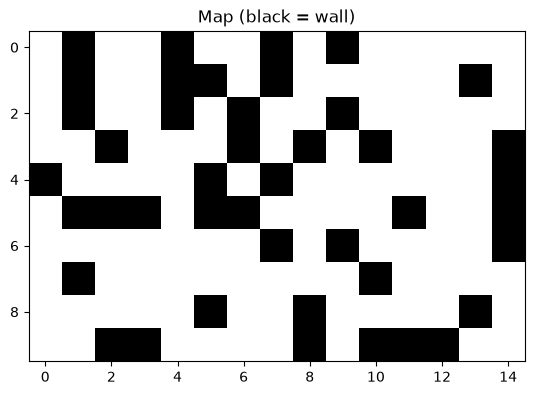

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import heapq
from collections import deque

ROWS, COLS = 10, 15          # map size
WALL_PROB = 0.30             # chance that a cell is a wall
SEED = 3                # makes the random map repeatable
START = (0, 0)               # (row, column)
GOAL = (ROWS - 1, COLS - 1)
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # up, down, left, right

rng = np.random.default_rng(SEED)
grid = (rng.random((ROWS, COLS)) < WALL_PROB).astype(int)   # 1 = wall
grid[START] = 0
grid[GOAL] = 0

plt.imshow(grid, cmap="Greys")
plt.title("Map (black = wall)")
plt.show()

## Cell 2: BFS and DFS in one function (only `popleft` vs `pop` differs)

In [2]:
def blind_search(grid, start, goal, mode):
    frontier = deque([start])
    came_from = {start: None}           # cell -> previous cell
    expanded = []                       # cells in the order we open them
    while frontier:
        if mode == "bfs":
            cell = frontier.popleft()   # oldest first (queue)
        else:
            cell = frontier.pop()       # newest first (stack)
        expanded.append(cell)
        if cell == goal:
            break
        for dr, dc in MOVES:
            nxt = (cell[0] + dr, cell[1] + dc)
            inside = 0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS
            if inside and grid[nxt] == 0 and nxt not in came_from:
                came_from[nxt] = cell
                frontier.append(nxt)
    if goal not in came_from:
        return None, expanded           # no path
    path = []
    cell = goal
    while cell is not None:
        path.append(cell)
        cell = came_from[cell]
    return path[::-1], expanded

## Cell 3: A* with the Manhattan heuristic

In [3]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def astar(grid, start, goal):
    heap = [(manhattan(start, goal), 0, start)]   # (f, g, cell)
    came_from = {start: None}
    best_g = {start: 0}                           # cheapest known cost to reach a cell
    expanded = []
    closed = set()
    while heap:
        f, g, cell = heapq.heappop(heap)          # smallest f first
        if cell in closed:
            continue
        closed.add(cell)
        expanded.append(cell)
        if cell == goal:
            break
        for dr, dc in MOVES:
            nxt = (cell[0] + dr, cell[1] + dc)
            inside = 0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS
            if inside and grid[nxt] == 0:
                new_g = g + 1
                if nxt not in best_g or new_g < best_g[nxt]:
                    best_g[nxt] = new_g
                    came_from[nxt] = cell
                    heapq.heappush(heap, (new_g + manhattan(nxt, goal), new_g, nxt))
    if goal not in came_from:
        return None, expanded
    path = []
    cell = goal
    while cell is not None:
        path.append(cell)
        cell = came_from[cell]
    return path[::-1], expanded

## Cell 4: Run the three algorithms

In [4]:
results = {}
for name in ["bfs", "dfs", "astar"]:
    if name == "astar":
        path, expanded = astar(grid, START, GOAL)
    else:
        path, expanded = blind_search(grid, START, GOAL, name)
    results[name] = (path, expanded)
    print(f"{name:6s} path length = {len(path) - 1:3d}   expanded cells = {len(expanded):3d}")

bfs    path length =  25   expanded cells =  90
dfs    path length =  25   expanded cells =  26
astar  path length =  25   expanded cells =  44


## Cell 5: Draw expanded cells and paths

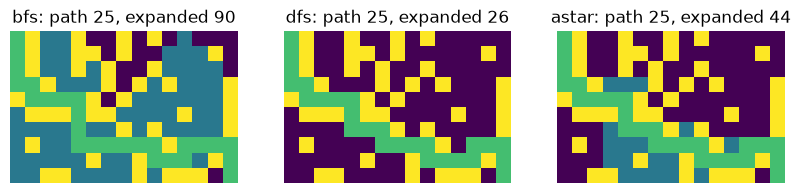

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, name in zip(axes, ["bfs", "dfs", "astar"]):
    path, expanded = results[name]
    picture = grid.astype(float)               # 0 free, 1 wall
    for cell in expanded:
        picture[cell] = 0.4                    # expanded cells
    for cell in path:
        picture[cell] = 0.7                    # final path
    ax.imshow(picture, cmap="viridis")
    ax.set_title(f"{name}: path {len(path) - 1}, expanded {len(expanded)}")
    ax.axis("off")
plt.show()

## Cell 6: 100 random maps

In [6]:
rows = []
for seed in range(100):
    rng = np.random.default_rng(seed)
    g = (rng.random((ROWS, COLS)) < WALL_PROB).astype(int)
    g[START] = 0
    g[GOAL] = 0
    for name in ["bfs", "dfs", "astar"]:
        if name == "astar":
            path, expanded = astar(g, START, GOAL)
        else:
            path, expanded = blind_search(g, START, GOAL, name)
        if path is not None:                      # skip maps with no path
            rows.append({"algo": name, "path": len(path) - 1, "expanded": len(expanded)})

df = pd.DataFrame(rows)
summary = df.groupby("algo")[["path", "expanded"]].mean().round(1)
print(summary)
print("solvable maps:", len(df) // 3)

       path  expanded
algo                 
astar  23.9      65.2
bfs    23.9      96.9
dfs    29.0      50.7
solvable maps: 53


## Cell 7: Chart of the averages

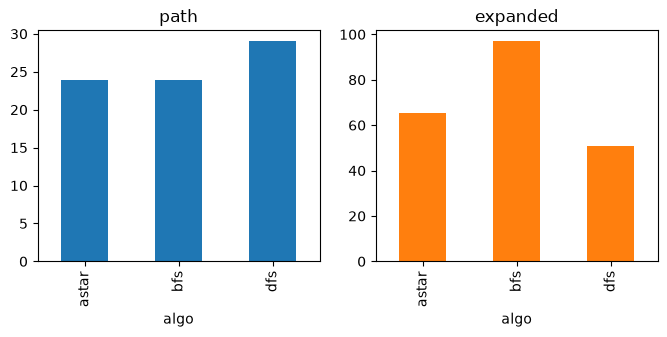

In [7]:
summary.plot(kind="bar", subplots=True, layout=(1, 2), figsize=(8, 3), legend=False)
plt.show()

# Part 2: Motion output
Run Part 1 first. This cell animates the order in which each algorithm opens cells.

## Cell 8: Animation (blue = expanded, orange = final path)

In [8]:
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from IPython.display import HTML

colors = ListedColormap(["white", "#1f2937", "#93c5fd", "#f59e0b"])   # free, wall, expanded, path
names = ["bfs", "dfs", "astar"]
fig, axes = plt.subplots(1, 3, figsize=(9, 3), dpi=60)

def draw(t):
    for ax, name in zip(axes, names):
        path, expanded = results[name]
        picture = grid.copy()                      # 0 free, 1 wall
        for cell in expanded[:t]:
            picture[cell] = 2
        if t >= len(expanded):
            for cell in path:
                picture[cell] = 3
        ax.clear()
        ax.imshow(picture, cmap=colors, vmin=0, vmax=3)
        ax.set_title(f"{name}: {min(t, len(expanded))} expanded", fontsize=9)
        ax.axis("off")

frames = max(len(results[n][1]) for n in names) + 10
anim = FuncAnimation(fig, draw, frames=frames, interval=80)
plt.close(fig)
HTML(anim.to_jshtml())

## Analysis questions
1. Why does A* open fewer cells?
2. Why are BFS and A* paths equally short?
3. Why is the DFS path longer?
4. What happens if WALL_PROB is 0.45?

## Challenges
More walls, different cell costs, diagonal moves, Euclidean heuristic.

# چالش توسعه: تاثیر تعداد موانع بر پیدا شدن مسیر

در این بخش احتمال وجود مانع را در چند مقدار مختلف بررسی می کنم. برای هر مقدار، چند نقشه با اندازه یکسان می سازم و با جستجوی BFS بررسی می کنم که آیا از نقطه شروع تا هدف مسیر وجود دارد یا نه.

اگر مسیر پیدا نشود، آن نقشه را بدون مسیر حساب می کنم. در پایان هم تعداد و درصد نقشه های بدون مسیر را کنار هم می گذارم تا مقایسه راحت تر باشد. برای اینکه نتیجه قابل تکرار باشد، از seed های مشخص استفاده شده است.



In [9]:
wall_probs = [0.10, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
tedad_map = 300
natayej_mavane = []

for prob in wall_probs:
    map_bedoon_masir = 0

    for seed in range(tedad_map):
        rng = np.random.default_rng(seed)
        test_grid = (rng.random((ROWS, COLS)) < prob).astype(int)

        test_grid[START] = 0
        test_grid[GOAL] = 0

        masir, _ = blind_search(test_grid, START, GOAL, "bfs")

        if masir is None:
            map_bedoon_masir += 1

    darsad_bedoon_masir = 100 * map_bedoon_masir / tedad_map
    natayej_mavane.append({
        "احتمال مانع": prob,
        "تعداد نقشه ها": tedad_map,
        "نقشه های بدون مسیر": map_bedoon_masir,
        "نقشه های دارای مسیر": tedad_map - map_bedoon_masir,
        "درصد بدون مسیر": round(darsad_bedoon_masir, 1)
    })

jadval_mavane = pd.DataFrame(natayej_mavane)
display(jadval_mavane)

,احتمال مانع,تعداد نقشه ها,نقشه های بدون مسیر,نقشه های دارای مسیر,درصد بدون مسیر
0,0.10,300,8,292,2.7
1,0.20,300,50,250,16.7
2,0.25,300,84,216,28.0
3,0.30,300,153,147,51.0
4,0.35,300,229,71,76.3
5,0.40,300,273,27,91.0
6,0.45,300,295,5,98.3
7,0.50,300,298,2,99.3


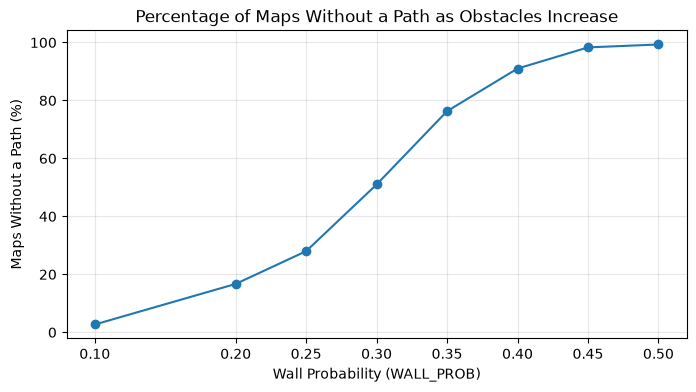

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(
    jadval_mavane["احتمال مانع"],
    jadval_mavane["درصد بدون مسیر"],
    marker="o"
)
plt.title("Percentage of Maps Without a Path as Obstacles Increase")
plt.xlabel("Wall Probability (WALL_PROB)")
plt.ylabel("Maps Without a Path (%)")
plt.xticks(wall_probs)
plt.grid(True, alpha=0.3)
plt.show()

## نتیجه گیری

با بیشتر شدن احتمال مانع، خانه های آزاد کمتری برای حرکت باقی می ماند و راه های جایگزین هم کمتر می شوند. به همین دلیل انتظار می رود درصد نقشه هایی که مسیر ندارند افزایش پیدا کند. البته نتیجه هر آزمایش به نقشه های تصادفی ساخته شده هم بستگی دارد؛ برای همین تعداد نقشه ها را 300 انتخاب کردم تا مقایسه از بررسی چند نقشه محدود قابل اعتمادتر باشد.

در جدول بالا می توان دید که در هر مقدار از WALL_PROB چند نقشه مسیر دارند و چند نقشه بدون مسیر هستند. درصد بدون مسیر از تقسیم تعداد نقشه های بدون مسیر بر کل نقشه ها و ضرب آن در 100 به دست می آید.